# Neural Ordinary Differential Equations (Neural ODEs)
### Structured implementation, experiments, and ablations
**Paper:** Chen et al., *Neural Ordinary Differential Equations*, NeurIPS 2018  
**Goal:** Build a small Neural ODE classifier, compare it with a ResNet, inspect adjoint gradients, and study a trajectory-fitting example. A small Latent ODE experiment is included as an extension.

>
> **Scope note:** The spiral task and damped-rotation trajectories are synthetic demonstrations, not an exact reproduction of a published MNIST result. The Latent ODE section is an extension inspired by later work; it is not part of the original 2018 Neural ODE paper.

## 1. Setup
Install the ODE solver library, import dependencies, choose the device, and set the random seed.

In [ ]:
%pip -q install torchdiffeq

In [ ]:
import sys
import time
import random
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torchdiffeq import odeint, odeint_adjoint

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Device:", device)
print("torchdiffeq: ready")

Python: 3.13.15
PyTorch: 2.11.0+cu130
Device: cuda
torchdiffeq: ready


## 2. Core idea: a neural network defines a continuous-time dynamics function

A Neural ODE replaces a stack of discrete hidden layers with an initial state and a learned differential equation:

\[
\frac{dh(t)}{dt}=f_\theta(h(t),t), \qquad h(t_1)=\operatorname{ODESolve}(f_\theta,h(t_0),t_0,t_1).
\]

The ODE solver numerically integrates the learned dynamics. For classification, we encode each input into a hidden state, evolve it through the ODE block, and classify the final state.

## 3. Create a synthetic two-class spiral dataset
The spirals form a nonlinear classification problem. We hold out 20% of the points for testing.

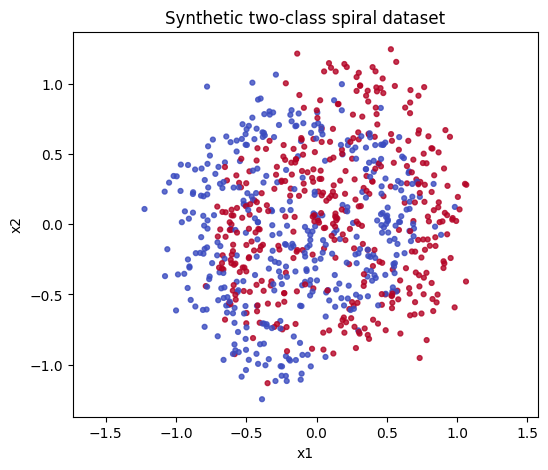

Train points: 640 | Test points: 160


In [ ]:
def make_spirals(n_per_class=400, noise=0.15):
    n = n_per_class
    theta = torch.sqrt(torch.rand(n)) * 3.5 * torch.pi
    radius = theta / (3.5 * torch.pi)

    x0 = torch.stack(
        [radius * torch.cos(theta), radius * torch.sin(theta)], dim=1
    )
    x1 = torch.stack(
        [radius * torch.cos(theta + torch.pi),
         radius * torch.sin(theta + torch.pi)], dim=1
    )
    X = torch.cat([x0, x1], dim=0)
    X += noise * torch.randn_like(X)
    y = torch.cat([
        torch.zeros(n, dtype=torch.long),
        torch.ones(n, dtype=torch.long)
    ])
    idx = torch.randperm(len(y))
    return X[idx], y[idx]

X, y = make_spirals()
perm = torch.randperm(len(y))
split = int(0.8 * len(y))
train_idx, test_idx = perm[:split], perm[split:]

X_train, y_train = X[train_idx].to(device), y[train_idx].to(device)
X_test, y_test = X[test_idx].to(device), y[test_idx].to(device)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12, alpha=0.8)
plt.title("Synthetic two-class spiral dataset")
plt.xlabel("x1")
plt.ylabel("x2")
plt.axis("equal")
plt.show()

print("Train points:", len(train_idx), "| Test points:", len(test_idx))

## 4. Define the Neural ODE and ResNet models

- **Neural ODE:** the hidden state follows a learned differential equation solved by RK4.
- **ResNet baseline:** the hidden state passes through four discrete residual blocks.
- Both models use the same input encoder and classifier dimensions to make the comparison more meaningful.

In [ ]:
class ODEFunc(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim)
        )

    def forward(self, t, h):
        return self.net(h)


class NeuralODEClassifier(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(2, hidden_dim), nn.Tanh())
        self.odefunc = ODEFunc(hidden_dim)
        self.classifier = nn.Linear(hidden_dim, 2)

    def forward(self, x, use_adjoint=False):
        h0 = self.encoder(x)
        times = torch.tensor([0.0, 1.0], device=x.device, dtype=x.dtype)
        solver = odeint_adjoint if use_adjoint else odeint
        h_path = solver(
            self.odefunc, h0, times, method="rk4",
            options={"step_size": 0.1}
        )
        return self.classifier(h_path[-1])


class ResidualBlock(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim)
        )

    def forward(self, h):
        return h + 0.1 * self.net(h)


class ResNetClassifier(nn.Module):
    def __init__(self, hidden_dim=64, num_blocks=4):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(2, hidden_dim), nn.Tanh())
        self.blocks = nn.Sequential(*[
            ResidualBlock(hidden_dim) for _ in range(num_blocks)
        ])
        self.classifier = nn.Linear(hidden_dim, 2)

    def forward(self, x):
        return self.classifier(self.blocks(self.encoder(x)))


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Neural ODE parameters:", count_parameters(NeuralODEClassifier().to(device)))
print("ResNet parameters:    ", count_parameters(ResNetClassifier().to(device)))

Neural ODE parameters: 8642
ResNet parameters:     33602


## 5. Train and evaluate the classifier models
We use cross-entropy loss and Adam. Test accuracy is calculated after training; it is not used to update the model.

In [ ]:
def train_classifier(model, epochs=500, lr=1e-3, label="model"):
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    history = {"loss": [], "train_acc": [], "test_acc": []}
    start = time.perf_counter()

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        logits = model(X_train)
        loss = criterion(logits, y_train)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            train_acc = (model(X_train).argmax(1) == y_train).float().mean().item()
            test_acc = (model(X_test).argmax(1) == y_test).float().mean().item()

        history["loss"].append(loss.item())
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)

        if (epoch + 1) % 55 == 0:
            print(
                f"{label} | epoch {epoch+1:3d}/{epochs} | "
                f"loss={loss.item():.4f} | train acc={train_acc:.3f} | "
                f"test acc={test_acc:.3f}"
            )

    elapsed = time.perf_counter() - start
    return model, history, elapsed


# Reset seed before each model so the comparison is easier to reproduce.
torch.manual_seed(SEED)
ode_model, ode_history, ode_seconds = train_classifier(
    NeuralODEClassifier(), label="Neural ODE"
)
torch.manual_seed(SEED)
resnet_model, resnet_history, resnet_seconds = train_classifier(
    ResNetClassifier(), label="ResNet"
)

def final_accuracy(model):
    model.eval()
    with torch.no_grad():
        return (model(X_test).argmax(1) == y_test).float().mean().item()

classifier_results = [
    ("Neural ODE", count_parameters(ode_model), final_accuracy(ode_model), ode_seconds),
    ("ResNet", count_parameters(resnet_model), final_accuracy(resnet_model), resnet_seconds),
]
print("\nFinal test results")
print(f"{'Model':<14} {'Parameters':>12} {'Test accuracy':>15} {'Seconds':>10}")
for name, params, acc, secs in classifier_results:
    print(f"{name:<14} {params:>12,d} {acc:>14.2%} {secs:>10.2f}")

Neural ODE | epoch  55/500 | loss=0.6319 | train acc=0.627 | test acc=0.550
Neural ODE | epoch 110/500 | loss=0.5493 | train acc=0.677 | test acc=0.650
Neural ODE | epoch 165/500 | loss=0.5407 | train acc=0.689 | test acc=0.675
Neural ODE | epoch 220/500 | loss=0.5336 | train acc=0.684 | test acc=0.675
Neural ODE | epoch 275/500 | loss=0.5261 | train acc=0.691 | test acc=0.688
Neural ODE | epoch 330/500 | loss=0.5166 | train acc=0.702 | test acc=0.700
Neural ODE | epoch 385/500 | loss=0.5041 | train acc=0.728 | test acc=0.700
Neural ODE | epoch 440/500 | loss=0.4834 | train acc=0.759 | test acc=0.719
Neural ODE | epoch 495/500 | loss=0.4598 | train acc=0.769 | test acc=0.725
ResNet | epoch  55/500 | loss=0.6395 | train acc=0.633 | test acc=0.575
ResNet | epoch 110/500 | loss=0.6383 | train acc=0.631 | test acc=0.575
ResNet | epoch 165/500 | loss=0.6351 | train acc=0.630 | test acc=0.575
ResNet | epoch 220/500 | loss=0.5937 | train acc=0.648 | test acc=0.562
ResNet | epoch 275/500 | los

## 6. Visualize learning curves and the learned decision regions

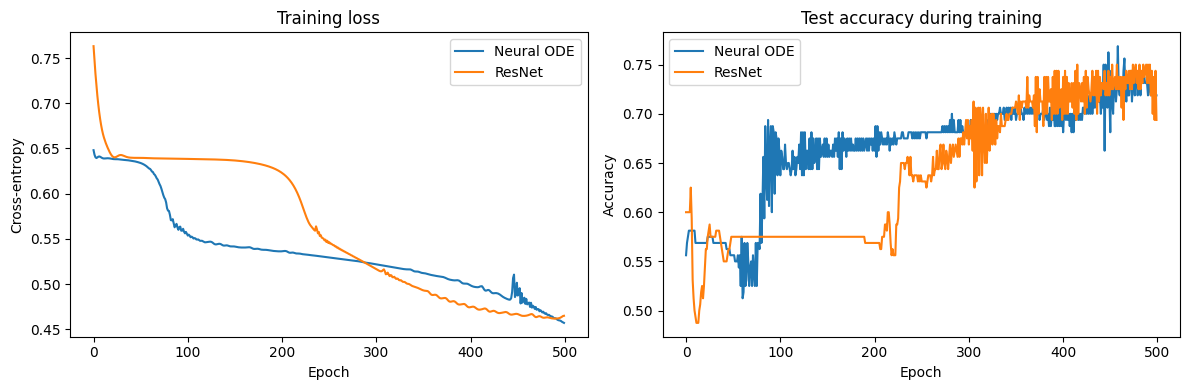

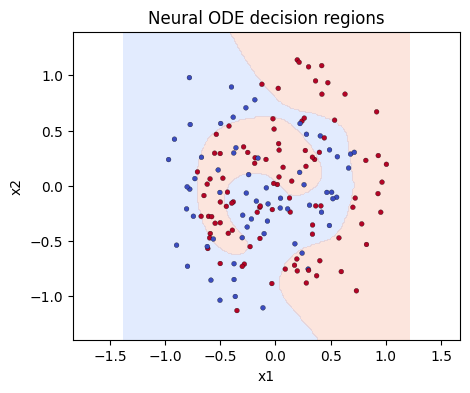

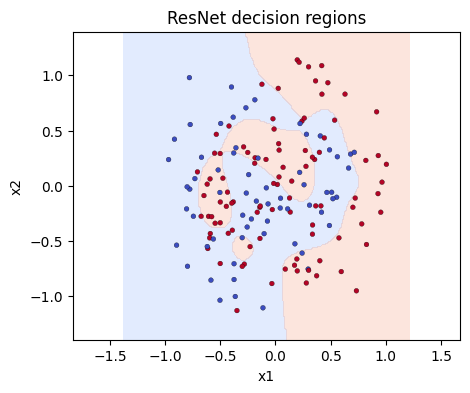

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ode_history["loss"], label="Neural ODE")
axes[0].plot(resnet_history["loss"], label="ResNet")
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy")
axes[0].legend()

axes[1].plot(ode_history["test_acc"], label="Neural ODE")
axes[1].plot(resnet_history["test_acc"], label="ResNet")
axes[1].set_title("Test accuracy during training")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()


def plot_decision_boundary(model, title):
    model.eval()
    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min().item() - 0.15, X[:, 0].max().item() + 0.15, 220),
        np.linspace(X[:, 1].min().item() - 0.15, X[:, 1].max().item() + 0.15, 220)
    )
    grid = torch.tensor(
        np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32, device=device
    )
    with torch.no_grad():
        pred = model(grid).argmax(1).cpu().numpy().reshape(xx.shape)

    plt.figure(figsize=(5, 4))
    plt.contourf(xx, yy, pred, levels=[-0.5, 0.5, 1.5], alpha=0.25, cmap="coolwarm")
    plt.scatter(X_test[:, 0].cpu(), X_test[:, 1].cpu(),
                c=y_test.cpu(), cmap="coolwarm", s=12, edgecolors="k", linewidths=0.2)
    plt.title(title)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.axis("equal")
    plt.show()

plot_decision_boundary(ode_model, "Neural ODE decision regions")
plot_decision_boundary(resnet_model, "ResNet decision regions")

## 7. Adjoint sensitivity: gradient and runtime comparison

The adjoint method computes gradients by solving an augmented differential equation backward in time. Here we compare the library's `odeint` and `odeint_adjoint` on the **same small batch and same initial parameters**.

**Important:** this uses the adjoint implementation supplied by `torchdiffeq`; it does not implement the adjoint derivation from scratch. Runtime for such a small problem is noisy and should not be interpreted as a universal speed comparison.

In [ ]:
torch.manual_seed(SEED)
base_model = NeuralODEClassifier().to(device)
model_direct = copy.deepcopy(base_model)
model_adjoint = copy.deepcopy(base_model)

xb, yb = X_train[:64], y_train[:64]
criterion = nn.CrossEntropyLoss()

def one_gradient_pass(model, use_adjoint):
    model.zero_grad(set_to_none=True)
    start = time.perf_counter()
    logits = model(xb, use_adjoint=use_adjoint)
    loss = criterion(logits, yb)
    loss.backward()
    elapsed = time.perf_counter() - start
    grad_sq = sum(
        (p.grad.detach().norm().item() ** 2)
        for p in model.parameters() if p.grad is not None
    )
    return loss.item(), grad_sq ** 0.5, elapsed

direct = one_gradient_pass(model_direct, use_adjoint=False)
adjoint = one_gradient_pass(model_adjoint, use_adjoint=True)

print(f"{'Method':<18} {'Loss':>10} {'Gradient norm':>16} {'Time (s)':>12}")
print(f"{'odeint':<18} {direct[0]:>10.6f} {direct[1]:>16.6f} {direct[2]:>12.4f}")
print(f"{'odeint_adjoint':<18} {adjoint[0]:>10.6f} {adjoint[1]:>16.6f} {adjoint[2]:>12.4f}")
print("Losses should match closely because both models started from identical weights.")

Method                   Loss    Gradient norm     Time (s)
odeint               0.663166         0.645644       0.0230
odeint_adjoint       0.663166         0.645644       0.1159
Losses should match closely because both models started from identical weights.


## 7A. Custom adjoint sensitivity for a scalar toy ODE (student implementation)

The classifier experiment above uses `torchdiffeq.odeint_adjoint`. This extra toy experiment implements the adjoint sensitivity calculation directly for a scalar ODE, so the backward sensitivity is visible rather than hidden inside a library.

Consider

\[
\frac{dh}{dt}=a h,\qquad h(0)=h_0,\qquad
L=\frac{1}{2}(h(T)-y)^2.
\]

For this scalar system, the forward solution is \(h(t)=h_0e^{at}\). The terminal adjoint is
\(\lambda(T)=\partial L/\partial h(T)=h(T)-y\), and it evolves backward as
\(d\lambda/dt=-a\lambda\). The parameter gradient is

\[
\frac{dL}{da}=\int_0^T \lambda(t)\,h(t)\,dt.
\]

The code below evaluates this integral with the trapezoidal rule and compares it with PyTorch autograd. This is an explicit, special-case toy implementation—not a general-purpose adjoint solver for arbitrary neural ODEs.


In [ ]:
import math
import torch

# Scalar toy problem: dh/dt = a*h, h(0)=h0.
dtype = torch.float64
h0 = torch.tensor(1.2, dtype=dtype)
target = torch.tensor(2.0, dtype=dtype)
a = torch.tensor(0.35, dtype=dtype, requires_grad=True)
T = 1.0
n_grid = 2001
t_grid = torch.linspace(0.0, T, n_grid, dtype=dtype)

# Reference gradient using ordinary autograd through the closed-form solution.
hT = h0 * torch.exp(a * T)
loss = 0.5 * (hT - target) ** 2
grad_autograd = torch.autograd.grad(loss, a)[0].detach()

# Student-written adjoint calculation for this scalar linear ODE.
# Forward state: h(t)=h0*exp(a*t)
# Backward adjoint: lambda(t)=lambda(T)*exp(a*(T-t))
with torch.no_grad():
    a_value = a.detach()
    h_values = h0 * torch.exp(a_value * t_grid)
    lambda_T = h_values[-1] - target
    lambda_values = lambda_T * torch.exp(a_value * (T - t_grid))
    integrand = lambda_values * h_values
    grad_adjoint = torch.trapezoid(integrand, t_grid)

print(f"Toy ODE terminal state: {hT.item():.6f}")
print(f"Loss: {loss.item():.8f}")
print(f"Gradient from PyTorch autograd: {grad_autograd.item():.8f}")
print(f"Gradient from custom adjoint integral: {grad_adjoint.item():.8f}")
print(f"Absolute gradient difference: {abs(grad_autograd.item()-grad_adjoint.item()):.3e}")

assert abs(grad_autograd.item() - grad_adjoint.item()) < 1e-5, "Custom adjoint gradient does not match autograd closely enough."


Toy ODE terminal state: 1.702881
Loss: 0.04413983
Gradient from PyTorch autograd: -0.50595822
Gradient from custom adjoint integral: -0.50595822
Absolute gradient difference: 1.110e-16


## 8. Fit a known trajectory with a neural differential equation

To test continuous dynamics independently of classification, we generate damped rotations from a known system:

\[
\frac{dx}{dt}=ax-\omega y,\qquad
\frac{dy}{dt}=\omega x+ay.
\]

A neural network learns the derivative from sampled trajectory points. We then integrate the learned vector field and compare the predicted path with the true path.

Epoch   0 | derivative MSE=1.808793
Epoch 100 | derivative MSE=0.000441
Epoch 200 | derivative MSE=0.000135
Epoch 300 | derivative MSE=0.000087
Integrated trajectory MSE: 0.000006


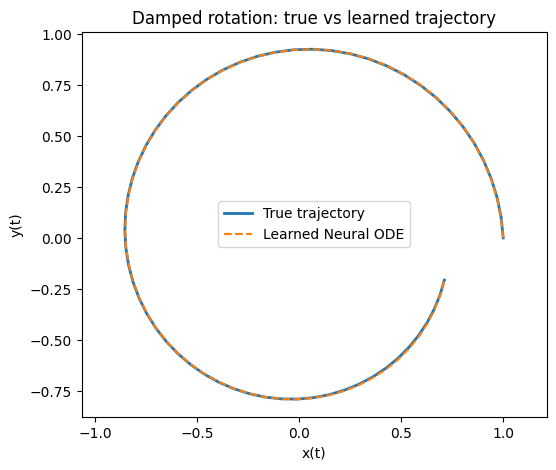

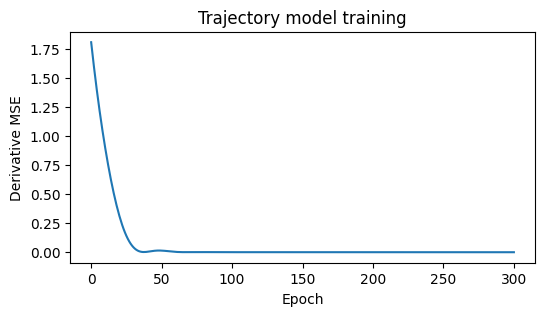

In [ ]:
torch.manual_seed(SEED)
a_true, omega_true = -0.1, 2.0
t_traj = torch.linspace(0.0, 3.0, 61, device=device)

def true_dynamics(t, state):
    x, y = state[..., 0], state[..., 1]
    dx = a_true * x - omega_true * y
    dy = omega_true * x + a_true * y
    return torch.stack([dx, dy], dim=-1)

initial_state = torch.tensor([1.0, 0.0], device=device)
with torch.no_grad():
    true_path = odeint(
        true_dynamics, initial_state, t_traj,
        method="rk4", options={"step_size": 0.01}
    )

class LearnedDynamics(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 2)
        )
    def forward(self, t, state):
        return self.net(state)

dynamics_model = LearnedDynamics().to(device)
optimizer_traj = optim.Adam(dynamics_model.parameters(), lr=1e-3)
trajectory_history = []
for epoch in range(301):
    optimizer_traj.zero_grad()
    pred_derivatives = dynamics_model(
        t_traj[:-1], true_path[:-1]
    )
    true_derivatives = true_dynamics(t_traj[:-1], true_path[:-1])
    loss = ((pred_derivatives - true_derivatives) ** 2).mean()
    loss.backward()
    optimizer_traj.step()
    trajectory_history.append(loss.item())
    if epoch in [0, 100, 200, 300]:
        print(f"Epoch {epoch:3d} | derivative MSE={loss.item():.6f}")

with torch.no_grad():
    learned_path = odeint(
        dynamics_model, initial_state, t_traj,
        method="rk4", options={"step_size": 0.05}
    )
    trajectory_mse = ((learned_path - true_path) ** 2).mean().item()

print(f"Integrated trajectory MSE: {trajectory_mse:.6f}")

plt.figure(figsize=(6, 5))
plt.plot(true_path[:, 0].cpu(), true_path[:, 1].cpu(), label="True trajectory", linewidth=2)
plt.plot(learned_path[:, 0].cpu(), learned_path[:, 1].cpu(), "--", label="Learned Neural ODE")
plt.xlabel("x(t)")
plt.ylabel("y(t)")
plt.title("Damped rotation: true vs learned trajectory")
plt.axis("equal")
plt.legend()
plt.show()

plt.figure(figsize=(6, 3))
plt.plot(trajectory_history)
plt.xlabel("Epoch")
plt.ylabel("Derivative MSE")
plt.title("Trajectory model training")
plt.show()

## 9. Solver step-size ablation

The ODE solver approximates continuous dynamics using finite steps. Keeping the learned vector field fixed, we evaluate several RK4 step sizes. Smaller steps usually require more function evaluations; prediction error need not improve monotonically because the learned dynamics also have approximation error.

In [ ]:
step_results = []
dynamics_model.eval()
for step_size in [0.20, 0.10, 0.05]:
    start = time.perf_counter()
    with torch.no_grad():
        path = odeint(
            dynamics_model, initial_state, t_traj,
            method="rk4", options={"step_size": step_size}
        )
    elapsed = time.perf_counter() - start
    mse = ((path - true_path) ** 2).mean().item()
    step_results.append((step_size, mse, elapsed))

print(f"{'RK4 step size':>14} {'Trajectory MSE':>17} {'Runtime (s)':>13}")
for step_size, mse, elapsed in step_results:
    print(f"{step_size:>14.2f} {mse:>17.7f} {elapsed:>13.4f}")

 RK4 step size    Trajectory MSE   Runtime (s)
          0.20         0.0000857        0.0332
          0.10         0.0000102        0.0434
          0.05         0.0000056        0.0667


## 10. Optional extension: a compact Latent ODE with a KL-weight ablation

This section is a small **extension**, not a reproduction of the 2018 paper's main experiments. We generate noisy observations from damped rotations. An encoder maps a complete observed sequence to a Gaussian latent initial state; a learned ODE evolves the latent state; a decoder reconstructs the trajectory.

The loss is reconstruction MSE plus a weighted KL divergence:

\[
\mathcal{L}=\mathcal{L}_{\mathrm{reconstruction}}+\beta D_{\mathrm{KL}}(q(z_0|x)\Vert p(z_0)).
\]

For a faster all-cells run, this section uses a small dataset and 120 training epochs per beta.

In [ ]:
torch.manual_seed(SEED)
latent_times = torch.linspace(0.0, 2.0, 21, device=device)
n_train, n_test = 160, 40

def generate_rotation_batch(n_samples, noise_std=0.03):
    init = (2 * torch.rand(n_samples, 2, device=device) - 1)
    paths = []
    for i in range(n_samples):
        paths.append(odeint(
            true_dynamics, init[i], latent_times,
            method="rk4", options={"step_size": 0.025}
        ))
    clean = torch.stack(paths, dim=0)  # [N, time, 2]
    noisy = clean + noise_std * torch.randn_like(clean)
    return clean, noisy

clean_all, noisy_all = generate_rotation_batch(n_train + n_test)
clean_train, noisy_train = clean_all[:n_train], noisy_all[:n_train]
clean_test, noisy_test = clean_all[n_train:], noisy_all[n_train:]
print("Latent ODE train/test shapes:", tuple(noisy_train.shape), tuple(noisy_test.shape))

Latent ODE train/test shapes: (160, 21, 2) (40, 21, 2)


In [ ]:
class LatentODE(nn.Module):
    def __init__(self, obs_dim=2, latent_dim=4, hidden_dim=48, n_times=21):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Linear(n_times * obs_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim), nn.Tanh()
        )
        self.mean_layer = nn.Linear(hidden_dim, latent_dim)
        self.logvar_layer = nn.Linear(hidden_dim, latent_dim)
        self.dynamics = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, obs_dim)
        )

    def encode(self, observations):
        h = self.encoder(observations.flatten(start_dim=1))
        return self.mean_layer(h), self.logvar_layer(h)

    def forward(self, observations, times, sample=True):
        mean, logvar = self.encode(observations)
        if sample:
            z0 = mean + torch.exp(0.5 * logvar) * torch.randn_like(mean)
        else:
            z0 = mean
        z_path = odeint(
            lambda t, z: self.dynamics(z), z0, times,
            method="rk4", options={"step_size": 0.05}
        )
        # odeint returns [time, batch, latent]; decoder preserves these leading dimensions.
        reconstruction = self.decoder(z_path)
        return reconstruction.permute(1, 0, 2), mean, logvar


def latent_loss(reconstruction, targets, mean, logvar, beta):
    recon = ((reconstruction - targets) ** 2).mean()
    kl = -0.5 * torch.mean(1 + logvar - mean.pow(2) - logvar.exp())
    return recon + beta * kl, recon, kl


def train_latent_beta(beta, epochs=120):
    torch.manual_seed(123)  # same starting weights for each beta
    model = LatentODE().to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        reconstruction, mean, logvar = model(noisy_train, latent_times, sample=True)
        loss, recon, kl = latent_loss(reconstruction, noisy_train, mean, logvar, beta)
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        reconstruction, mean, logvar = model(noisy_test, latent_times, sample=False)
        clean_mse = ((reconstruction - clean_test) ** 2).mean().item()
        noisy_mse = ((reconstruction - noisy_test) ** 2).mean().item()
        kl_value = (-0.5 * torch.mean(
            1 + logvar - mean.pow(2) - logvar.exp()
        )).item()
    return model, clean_mse, noisy_mse, kl_value

latent_results = []
latent_models = {}
for beta in [1e-3, 1e-4]:
    start = time.perf_counter()
    model, clean_mse, noisy_mse, kl_value = train_latent_beta(beta)
    elapsed = time.perf_counter() - start
    latent_models[beta] = model
    latent_results.append((beta, clean_mse, noisy_mse, kl_value, elapsed))
    print(f"beta={beta:g} | clean test MSE={clean_mse:.6f} | "
          f"noisy test MSE={noisy_mse:.6f} | KL={kl_value:.4f} | "
          f"time={elapsed:.1f}s")

print("\nKL-weight ablation")
print(f"{'beta':>10} {'Clean MSE':>12} {'Noisy MSE':>12} {'KL':>10} {'Seconds':>10}")
for row in latent_results:
    print(f"{row[0]:>10.4g} {row[1]:>12.6f} {row[2]:>12.6f} {row[3]:>10.4f} {row[4]:>10.1f}")

beta=0.001 | clean test MSE=0.025113 | noisy test MSE=0.025628 | KL=2.0222 | time=15.5s
beta=0.0001 | clean test MSE=0.026189 | noisy test MSE=0.026697 | KL=2.2602 | time=15.5s

KL-weight ablation
      beta    Clean MSE    Noisy MSE         KL    Seconds
     0.001     0.025113     0.025628     2.0222       15.5
    0.0001     0.026189     0.026697     2.2602       15.5


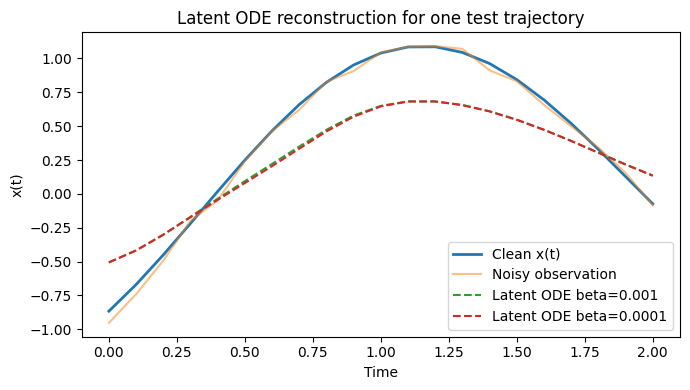

In [ ]:
# Plot one held-out trajectory reconstructed by each beta setting.
sample_idx = 0
plt.figure(figsize=(7, 4))
plt.plot(latent_times.cpu(), clean_test[sample_idx, :, 0].cpu(),
         label="Clean x(t)", linewidth=2)
plt.plot(latent_times.cpu(), noisy_test[sample_idx, :, 0].cpu(),
         label="Noisy observation", alpha=0.5)
for beta, model in latent_models.items():
    model.eval()
    with torch.no_grad():
        rec, _, _ = model(noisy_test[sample_idx:sample_idx+1], latent_times, sample=False)
    plt.plot(latent_times.cpu(), rec[0, :, 0].cpu(), "--", label=f"Latent ODE beta={beta:g}")
plt.title("Latent ODE reconstruction for one test trajectory")
plt.xlabel("Time")
plt.ylabel("x(t)")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Additional benchmark: MNIST classification

This experiment adds a standard image-classification benchmark alongside the synthetic spiral experiment. Both models use the same MNIST split, preprocessing, optimizer, number of epochs, and evaluation procedure.

- **Neural ODE:** CNN image encoder → continuous-depth ODE block → classifier.
- **ResNet baseline:** the same CNN image encoder → residual MLP blocks → classifier.

This is a **small, reduced-scale comparison**, not an exact reproduction of the paper's MNIST experiment. The architecture, training budget, and implementation differ from the original paper. We report our measured results and do not expect them to match the paper's table exactly.

If Colab asks to download MNIST, allow it. For a quick first run, use the default small epoch count below. You can increase it only if time permits.

In [ ]:
# MNIST data: shared train/test split and normalization for both models.
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

MNIST_BATCH_SIZE = 128
MNIST_EPOCHS = 5       # Deadline-friendly starting point; increase to 8-10 only if time permits.
MNIST_TRAIN_LIMIT = 20000  # Use 20000 training examples for a faster, controlled experiment.
MNIST_TEST_LIMIT = 5000

mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

mnist_train_full = datasets.MNIST(
    root="./data", train=True, download=True, transform=mnist_transform
)
mnist_test_full = datasets.MNIST(
    root="./data", train=False, download=True, transform=mnist_transform
)

# Fixed, seeded subsets make this reduced-scale experiment repeatable.
mnist_generator = torch.Generator().manual_seed(SEED)
train_indices = torch.randperm(len(mnist_train_full), generator=mnist_generator)[:MNIST_TRAIN_LIMIT].tolist()
test_indices = torch.arange(min(MNIST_TEST_LIMIT, len(mnist_test_full))).tolist()

mnist_train_loader = DataLoader(
    Subset(mnist_train_full, train_indices),
    batch_size=MNIST_BATCH_SIZE, shuffle=True, num_workers=2,
    pin_memory=(device.type == "cuda")
)
mnist_test_loader = DataLoader(
    Subset(mnist_test_full, test_indices),
    batch_size=256, shuffle=False, num_workers=2,
    pin_memory=(device.type == "cuda")
)

print(f"Device: {device}")
print(f"MNIST train examples: {len(train_indices)}")
print(f"MNIST test examples: {len(test_indices)}")
print(f"Epochs per model: {MNIST_EPOCHS}")

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.84MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 124kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.20MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.69MB/s]

Device: cuda
MNIST train examples: 20000
MNIST test examples: 5000
Epochs per model: 5


In [ ]:
# Shared CNN encoder; the models differ only in their hidden-state processing block.
class MNISTEncoder(nn.Module):
    def __init__(self, feature_dim=64):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                 # 28x28 -> 14x14
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                 # 14x14 -> 7x7
            nn.AdaptiveAvgPool2d((2, 2)),
            nn.Flatten(),
            nn.Linear(32 * 2 * 2, feature_dim),
            nn.Tanh()
        )

    def forward(self, x):
        return self.features(x)


class MNISTODEFunc(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim)
        )

    def forward(self, t, h):
        return self.net(h)


class MNISTNeuralODE(nn.Module):
    def __init__(self, hidden_dim=64, step_size=0.25):
        super().__init__()
        self.encoder = MNISTEncoder(hidden_dim)
        self.odefunc = MNISTODEFunc(hidden_dim)
        self.step_size = step_size
        self.classifier = nn.Linear(hidden_dim, 10)

    def forward(self, x):
        h0 = self.encoder(x)
        times = torch.tensor([0.0, 1.0], device=h0.device, dtype=h0.dtype)
        h1 = odeint(
            self.odefunc, h0, times, method="rk4",
            options={"step_size": self.step_size}
        )[-1]
        return self.classifier(h1)


class MNISTResidualBlock(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim)
        )

    def forward(self, h):
        return h + 0.1 * self.net(h)


class MNISTResNet(nn.Module):
    def __init__(self, hidden_dim=64, num_blocks=4):
        super().__init__()
        self.encoder = MNISTEncoder(hidden_dim)
        self.blocks = nn.Sequential(*[
            MNISTResidualBlock(hidden_dim) for _ in range(num_blocks)
        ])
        self.classifier = nn.Linear(hidden_dim, 10)

    def forward(self, x):
        h = self.encoder(x)
        h = self.blocks(h)
        return self.classifier(h)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print("MNIST models defined.")

MNIST models defined.


In [ ]:
def run_mnist_experiment(model, model_name, epochs=MNIST_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "test_accuracy": []}

    if device.type == "cuda":
        torch.cuda.synchronize()
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        total_loss, total_seen = 0.0, 0

        for images, labels in mnist_train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * labels.size(0)
            total_seen += labels.size(0)

        mean_loss = total_loss / max(total_seen, 1)

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for images, labels in mnist_test_loader:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)
                predictions = model(images).argmax(dim=1)
                correct += (predictions == labels).sum().item()
                total += labels.size(0)

        accuracy = 100.0 * correct / max(total, 1)
        history["train_loss"].append(mean_loss)
        history["test_accuracy"].append(accuracy)
        print(f"{model_name} | epoch {epoch+1:02d}/{epochs} | "
              f"train loss={mean_loss:.4f} | test accuracy={accuracy:.2f}%")

    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.time() - start_time

    result = {
        "model": model_name,
        "test_accuracy_percent": history["test_accuracy"][-1],
        "test_error_percent": 100.0 - history["test_accuracy"][-1],
        "parameters": count_parameters(model),
        "training_seconds": elapsed,
        "epochs": epochs,
        "train_examples": len(train_indices),
        "test_examples": len(test_indices),
    }
    return model, history, result


# Reset to the same seed before model creation for a reproducible starting point.
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
mnist_ode_model = MNISTNeuralODE()
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
mnist_resnet_model = MNISTResNet()

print("Neural ODE parameters:", count_parameters(mnist_ode_model))
print("ResNet parameters:", count_parameters(mnist_resnet_model))

Neural ODE parameters: 22026
ResNet parameters: 46986


In [ ]:
# Train both models under the same data and epoch budget.
mnist_ode_model, mnist_ode_history, mnist_ode_result = run_mnist_experiment(
    mnist_ode_model, "Neural ODE"
)
mnist_resnet_model, mnist_resnet_history, mnist_resnet_result = run_mnist_experiment(
    mnist_resnet_model, "ResNet"
)

mnist_results = [mnist_ode_result, mnist_resnet_result]
print("\nMNIST RESULTS — measured on this run")
print(f"{'Model':<14} {'Accuracy':>10} {'Error':>10} {'Params':>12} {'Time (s)':>12}")
for result in mnist_results:
    print(f"{result['model']:<14} "
          f"{result['test_accuracy_percent']:>9.2f}% "
          f"{result['test_error_percent']:>9.2f}% "
          f"{result['parameters']:>12,} "
          f"{result['training_seconds']:>12.2f}")

Neural ODE | epoch 01/5 | train loss=1.3109 | test accuracy=77.40%
Neural ODE | epoch 02/5 | train loss=0.3969 | test accuracy=89.16%
Neural ODE | epoch 03/5 | train loss=0.2576 | test accuracy=92.14%
Neural ODE | epoch 04/5 | train loss=0.2020 | test accuracy=92.76%
Neural ODE | epoch 05/5 | train loss=0.1762 | test accuracy=92.96%
ResNet | epoch 01/5 | train loss=1.3090 | test accuracy=81.74%
ResNet | epoch 02/5 | train loss=0.3620 | test accuracy=88.48%
ResNet | epoch 03/5 | train loss=0.2405 | test accuracy=91.72%
ResNet | epoch 04/5 | train loss=0.1995 | test accuracy=92.28%
ResNet | epoch 05/5 | train loss=0.1575 | test accuracy=93.64%

MNIST RESULTS — measured on this run
Model            Accuracy      Error       Params     Time (s)
Neural ODE         92.96%      7.04%       22,026        39.62
ResNet             93.64%      6.36%       46,986        28.20


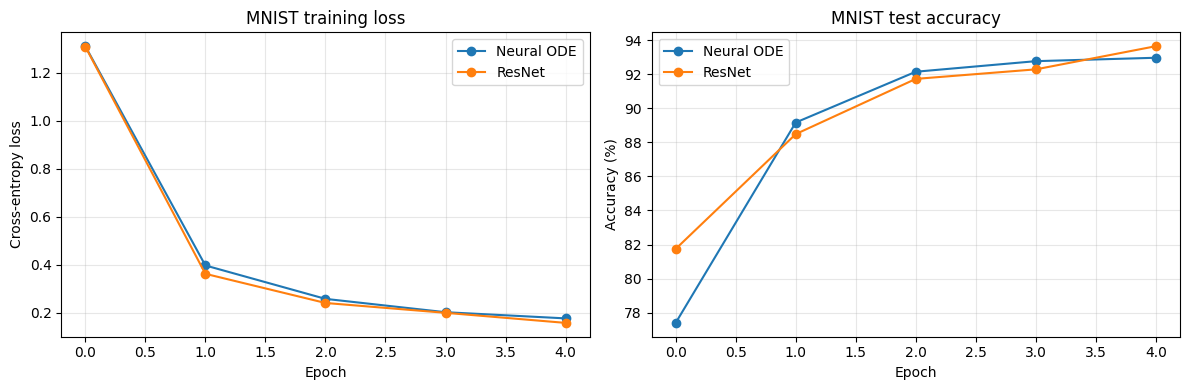

In [ ]:
# Plot training loss and test accuracy for the two models.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(mnist_ode_history["train_loss"], marker="o", label="Neural ODE")
axes[0].plot(mnist_resnet_history["train_loss"], marker="o", label="ResNet")
axes[0].set_title("MNIST training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(mnist_ode_history["test_accuracy"], marker="o", label="Neural ODE")
axes[1].plot(mnist_resnet_history["test_accuracy"], marker="o", label="ResNet")
axes[1].set_title("MNIST test accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 11A. Comparison with the original paper

The original paper's Table 1 reports MNIST test error and parameter count for its own architectures. The results below compare those published values with the **saved results from this notebook's current run**. This is a contextual comparison, not an exact reproduction.

| Experiment / model | Test error | Trainable parameters |
|---|---:|---:|
| Original paper: ResNet | 0.41% | 0.60 M |
| Original paper: RK-Net | 0.47% | 0.22 M |
| Original paper: ODE-Net | 0.42% | 0.22 M |
| This notebook: Neural ODE | 7.04% | 22,026 |
| This notebook: ResNet baseline | 6.36% | 46,986 |

**Changes in our experiment:** 20,000 training examples, 5,000 test examples, five epochs, and smaller/custom model architectures. The notebook's Neural ODE is a compact CNN encoder followed by an ODE block, while its ResNet baseline uses a different residual architecture from the paper. Therefore, these values should not be treated as an apples-to-apples reproduction.

**Interpretation of this run:** the Neural ODE uses about 53.1% fewer trainable parameters than this notebook's ResNet baseline, but its test accuracy is 0.68 percentage points lower (92.96% versus 93.64%). Its measured training time is also longer in this run (39.62 s versus 28.20 s). Timing is environment-dependent and should not be generalized from one run.

**Source:** Chen et al., “Neural Ordinary Differential Equations,” NeurIPS 2018, Table 1, https://arxiv.org/abs/1806.07366.


## 14. References

1. R. T. Q. Chen, Y. Rubanova, J. Bettencourt, and D. Duvenaud, “Neural Ordinary Differential Equations,” *Advances in Neural Information Processing Systems (NeurIPS)*, 2018. https://arxiv.org/abs/1806.07366
2. Y. Rubanova, R. T. Q. Chen, and D. Duvenaud, “Latent Ordinary Differential Equations for Irregularly-Sampled Time Series,” *NeurIPS*, 2019. https://arxiv.org/abs/1907.03907
3. `torchdiffeq` library documentation and implementation: https://github.com/rtqichen/torchdiffeq